# 4.2 — Gaussian RNG (Box–Muller)

Functions live in `functions.py`; this notebook runs them and keeps the data and figures.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from functions import *

In [2]:
# Parameters (quote these in the report captions)
SEED = 1
N = 100_000
N_TRIES = 1_000_000

rng = np.random.default_rng(SEED)
set_plot_style()

## (a) Program the algorithm and show that it generates pairs of normally distributed random variables.

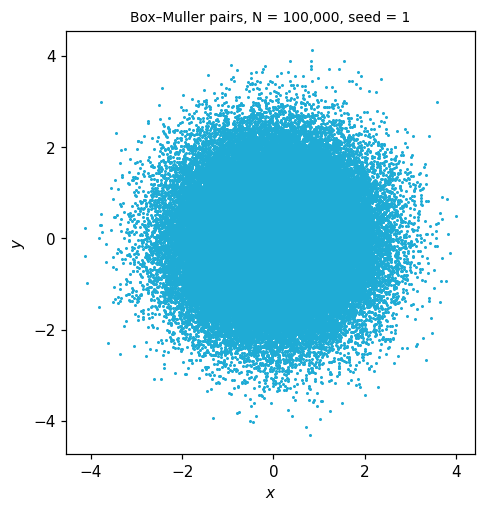

In [3]:
# two INDEPENDENT uniforms: one for the radius, one for the angle
u1 = rng.random(N)
u2 = rng.random(N)
r = np.sqrt(-2*np.log(1-u1))
theta = 2*np.pi*u2

x = r*np.cos(theta)
y = r*np.sin(theta)

fig = plot_xy(x, y, title=f"Box–Muller pairs, N = {N:,}, seed = {SEED}")
save_figure(fig, "box_muller_xy")

x: mean = -0.0033 ± 0.0032,  var = 0.9954
y: mean = +0.0072 ± 0.0032,  var = 1.0036
corr(x, y) = -0.0016  (expected 0 ± 0.0032)


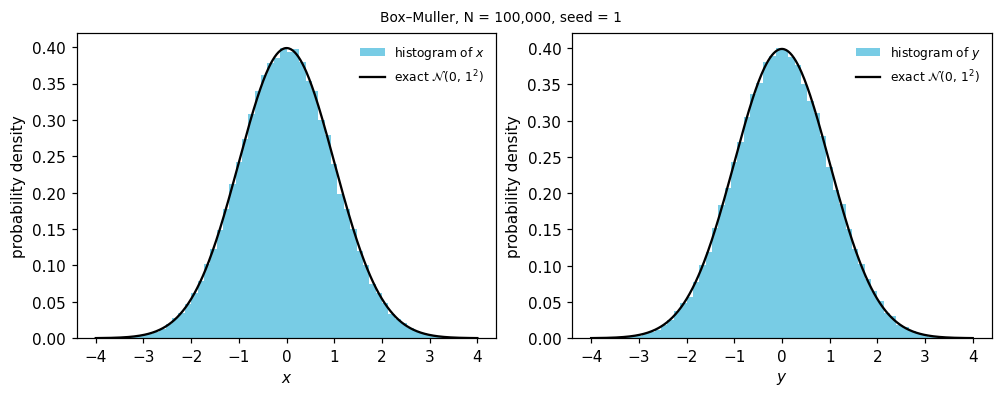

In [4]:
# collapse onto one axis:
fig = plot_hist_xy(x, y, title=f"Box–Muller, N = {N:,}, seed = {SEED}")
save_figure(fig, "box_muller_hist")

for name, d in (("x", x), ("y", y)):
    print(f"{name}: mean = {d.mean():+.4f} ± {d.std(ddof=1)/np.sqrt(N):.4f},  var = {d.var(ddof=1):.4f}")

rho = np.corrcoef(x, y)[0, 1]
print(f"corr(x, y) = {rho:+.4f}  (expected 0 ± {1/np.sqrt(N):.4f})")

## (b) How must the algorithm be adapted to obtain Gaussian numbers with mean $\mu$ and variance $\sigma^2$?

x': mean = 2.9934 ± 0.0063 (expected 3),  var = 3.9814 (expected 4)
y': mean = 3.0145 ± 0.0063 (expected 3),  var = 4.0142 (expected 4)


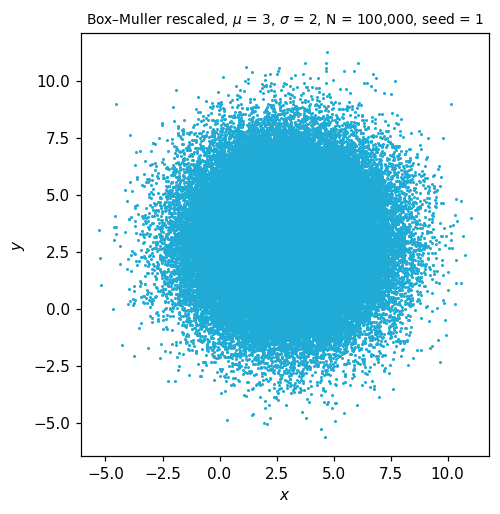

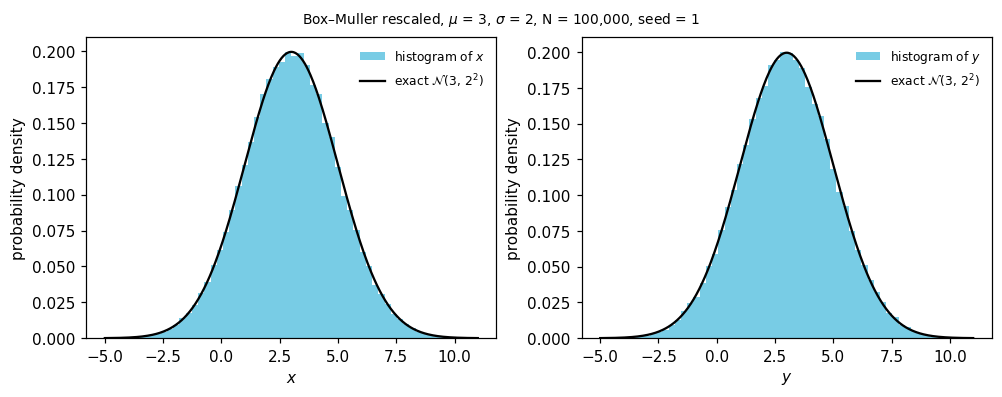

In [5]:
MU, SIGMA = 3.0, 2.0     # target mean and standard deviation for (b)
# same Box-Muller pairs, rescaled and shifted
x_b = MU + SIGMA*x
y_b = MU + SIGMA*y

fig = plot_xy(x_b, y_b, title=rf"Box–Muller rescaled, $\mu$ = {MU:g}, $\sigma$ = {SIGMA:g}, N = {N:,}, seed = {SEED}")
save_figure(fig, "box_muller_xy_mu_sigma")

fig = plot_hist_xy(x_b, y_b, mu=MU, sigma=SIGMA, title=rf"Box–Muller rescaled, $\mu$ = {MU:g}, $\sigma$ = {SIGMA:g}, N = {N:,}, seed = {SEED}")
save_figure(fig, "box_muller_hist_mu_sigma")

# expect mean MU and variance SIGMA^2
for name, d in (("x'", x_b), ("y'", y_b)):
    print(f"{name}: mean = {d.mean():.4f} ± {d.std(ddof=1)/np.sqrt(N):.4f} (expected {MU:g}),  "
          f"var = {d.var(ddof=1):.4f} (expected {SIGMA**2:g})")

x': mean = 2.9934 ± 0.0063 (expected 3),  var = 3.9814 (expected 4)
y': mean = -4.9928 ± 0.0032 (expected -5),  var = 1.0036 (expected 1)


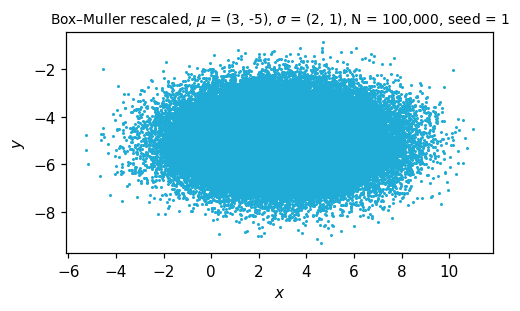

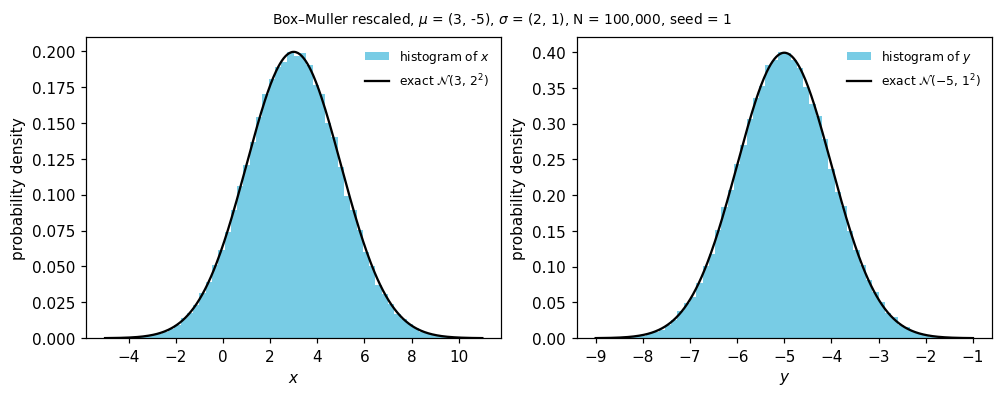

In [6]:
# For a non axially symmetrical distribution: a different mean and sigma for x and y

MU = np.array([3.0, -5.0])      # (mu_x, mu_y)
SIGMA = np.array([2.0, 1.0])    # (sigma_x, sigma_y), must be > 0
# same Box-Muller pairs, rescaled and shifted per axis
x_b = MU[0] + SIGMA[0]*x
y_b = MU[1] + SIGMA[1]*y

info = (rf"$\mu$ = ({MU[0]:g}, {MU[1]:g}), $\sigma$ = ({SIGMA[0]:g}, {SIGMA[1]:g}), "
        f"N = {N:,}, seed = {SEED}")

fig = plot_xy(x_b, y_b, title="Box–Muller rescaled, " + info)
save_figure(fig, "box_muller_xy_mu_sigma_asym")

fig = plot_hist_xy(x_b, y_b, mu=MU, sigma=SIGMA, title="Box–Muller rescaled, " + info)
save_figure(fig, "box_muller_hist_mu_sigma_asym")

# expect mean MU[i] and variance SIGMA[i]^2 for each axis
for name, d, m, s in (("x'", x_b, MU[0], SIGMA[0]), ("y'", y_b, MU[1], SIGMA[1])):
    print(f"{name}: mean = {d.mean():.4f} ± {d.std(ddof=1)/np.sqrt(N):.4f} (expected {m:g}),  "
          f"var = {d.var(ddof=1):.4f} (expected {s**2:g})")